In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")



from pathlib import Path

project_path = Path.cwd()

print("Current folder:", project_path)
print("\nCSV files found in this folder and its subfolders:")

for file in project_path.rglob("*.csv"):
    print(file)



df = pd.read_csv("data/sales.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)



Libraries imported successfully!
Current folder: c:\Users\USER\OneDrive\Desktop\CodeNova_Sales_Analysis\CodeNova_Task_4

CSV files found in this folder and its subfolders:
c:\Users\USER\OneDrive\Desktop\CodeNova_Sales_Analysis\CodeNova_Task_4\data\sales.csv
Dataset loaded successfully!
Number of rows and columns: (10194, 21)


In [7]:

print("Column names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First five rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [8]:

# Check the data types of our important columns
print("Data types:")
print(df[["Customer ID", "Order ID", "Order Date", "Sales"]].dtypes)

# Check for missing values
print("\nMissing values:")
print(df[["Customer ID", "Order ID", "Order Date", "Sales"]].isnull().sum())

# Check the date range
print("\nOrder date range:")
print("Earliest order:", df["Order Date"].min())
print("Latest order:", df["Order Date"].max())


Data types:
Customer ID        str
Order ID           str
Order Date         str
Sales          float64
dtype: object

Missing values:
Customer ID    0
Order ID       0
Order Date     0
Sales          0
dtype: int64

Order date range:
Earliest order: 1/1/2026
Latest order: 9/9/2026


In [9]:


# Convert Order Date from text to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)

# Check the result
print("Data type:", df["Order Date"].dtype)

print("\nEarliest order:", df["Order Date"].min())
print("Latest order:", df["Order Date"].max())

display(df[["Order Date"]].head())


Data type: datetime64[us]

Earliest order: 2023-01-03 00:00:00
Latest order: 2026-12-30 00:00:00


,Order Date
0,2023-01-03
1,2023-01-04
2,2023-01-04
3,2023-01-04
4,2023-01-05


In [10]:

from datetime import datetime

# Today's date
today = pd.Timestamp.today().normalize()

# Find orders dated after today
future_orders = df[df["Order Date"] > today]

print("Today's date:", today.date())
print("Total rows:", len(df))
print("Future-dated rows:", len(future_orders))

print("\nEarliest future order:")
print(future_orders["Order Date"].min())

print("\nLatest future order:")
print(future_orders["Order Date"].max())


Today's date: 2026-10-23
Total rows: 10194
Future-dated rows: 1001

Earliest future order:
2026-10-24 00:00:00

Latest future order:
2026-12-30 00:00:00


In [11]:

# Keep orders dated today or earlier
analysis_df = df[df["Order Date"] <= today].copy()

print("Original rows:", len(df))
print("Rows used for analysis:", len(analysis_df))
print("Rows excluded:", len(df) - len(analysis_df))

print("\nDate range used:")
print("Earliest:", analysis_df["Order Date"].min())
print("Latest:", analysis_df["Order Date"].max())


Original rows: 10194
Rows used for analysis: 9193
Rows excluded: 1001

Date range used:
Earliest: 2023-01-03 00:00:00
Latest: 2026-10-23 00:00:00


In [12]:

# Set the reference date for RFM calculations
analysis_date = analysis_df["Order Date"].max() + pd.Timedelta(days=1)

# Calculate RFM for each customer
rfm = analysis_df.groupby("Customer ID").agg(
    Recency=("Order Date", lambda dates: (analysis_date - dates.max()).days),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

# Display the first five customers
display(rfm.head())

# Check the size of the RFM table
print("Number of customers:", len(rfm))
print("Number of RFM columns:", len(rfm.columns))


,Customer ID,Recency,Frequency,Monetary
0,AA-10315,117,5,5563.560
1,AA-10375,47,8,906.518
2,AA-10480,192,4,1790.512
3,AA-10645,415,5,5073.975
4,AB-10015,348,3,886.156


Number of customers: 803
Number of RFM columns: 4


In [13]:

%pip install scikit-learn


from sklearn.preprocessing import StandardScaler

# Select only the numerical features for clustering
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Create the scaler
scaler = StandardScaler()

# Fit the scaler and transform the features
rfm_scaled = scaler.fit_transform(rfm_features)

print("Original RFM shape:", rfm_features.shape)
print("Scaled RFM shape:", rfm_scaled.shape)

# Display the first five scaled rows
display(pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
).head())


Note: you may need to restart the kernel to use updated packages.
Original RFM shape: (803, 3)
Scaled RFM shape: (803, 3)



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,Recency,Frequency,Monetary
0,-0.329791,-0.287490,1.137988
1,-0.668296,0.912792,-0.671181
2,0.032893,-0.687584,-0.327767
3,1.111274,-0.287490,0.947794
4,0.787276,-1.087678,-0.679091


In [14]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Clustering tools imported successfully!")


Clustering tools imported successfully!


In [15]:

# Store the results from each experiment
inertia_values = []
silhouette_scores = []
k_values = range(2, 11)

# Test between 2 and 10 clusters
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    # Record the Elbow Method value
    inertia_values.append(kmeans.inertia_)

    # Record the Silhouette Score
    score = silhouette_score(rfm_scaled, cluster_labels)
    silhouette_scores.append(score)

print("Experiment completed!")
print("Number of cluster counts tested:", len(inertia_values))


Experiment completed!
Number of cluster counts tested: 9


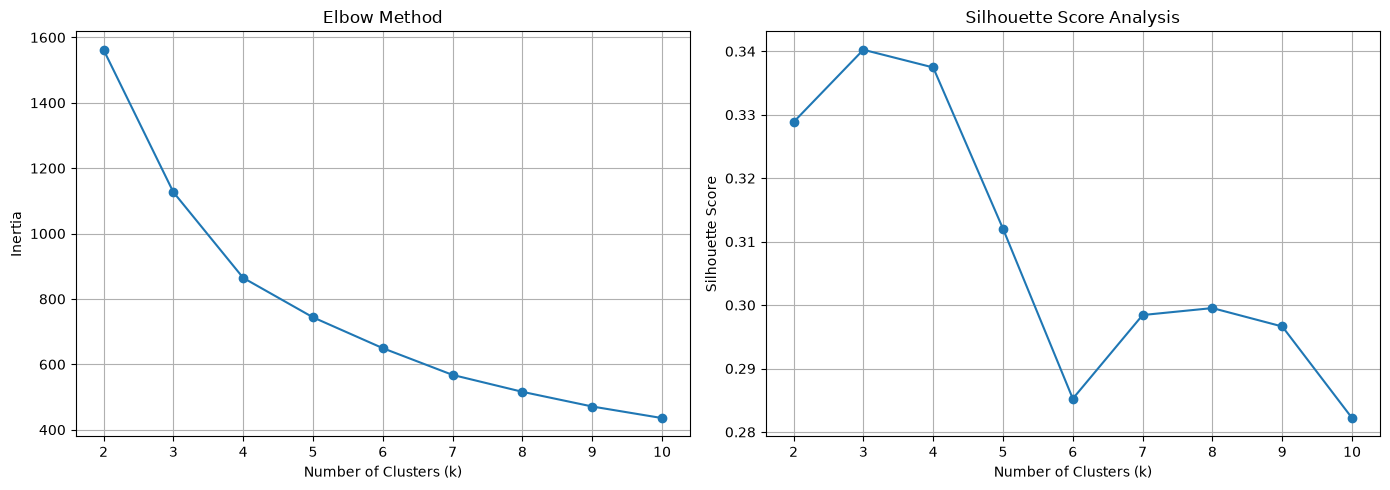

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method plot
axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)
plt.savefig("output/elbow_method.png",
            dpi=300, bbox_inches="tight")

# Silhouette Score plot
axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Score Analysis")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)
plt.savefig("output/silhouette_analysis.png",
            dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [17]:

# Build a 3-cluster model
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_3 = kmeans_3.fit_predict(rfm_scaled)

# Build a 4-cluster model
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_4 = kmeans_4.fit_predict(rfm_scaled)

# Compare their Silhouette Scores
score_3 = silhouette_score(rfm_scaled, labels_3)
score_4 = silhouette_score(rfm_scaled, labels_4)

print("3-cluster Silhouette Score:", round(score_3, 4))
print("4-cluster Silhouette Score:", round(score_4, 4))


3-cluster Silhouette Score: 0.3402
4-cluster Silhouette Score: 0.3375


In [18]:

# Copy the RFM table so the original stays unchanged
rfm_3 = rfm.copy()

# Assign the cluster labels from our 3-cluster model
rfm_3["Cluster"] = labels_3

# Display a sample
display(rfm_3.head(10))

# Count the customers in each cluster
print("\nNumber of customers in each cluster:")
print(rfm_3["Cluster"].value_counts().sort_index())


,Customer ID,Recency,Frequency,Monetary,Cluster
0,AA-10315,117,5,5563.560,2
1,AA-10375,47,8,906.518,1
2,AA-10480,192,4,1790.512,1
3,AA-10645,415,5,5073.975,0
4,AB-10015,348,3,886.156,0
5,AB-10060,38,6,4920.082,2
6,AB-10105,35,9,13629.731,2
7,AB-10150,50,4,828.014,1
8,AB-10165,39,8,1168.246,1
9,AB-10255,99,9,914.532,2



Number of customers in each cluster:
Cluster
0    136
1    415
2    252
Name: count, dtype: int64


In [19]:

# Copy the RFM table so the original stays unchanged
rfm_3 = rfm.copy()

# Assign the cluster labels from our 3-cluster model
rfm_3["Cluster"] = labels_3

# Display a sample
display(rfm_3.head(10))

# Count the customers in each cluster
print("\nNumber of customers in each cluster:")
print(rfm_3["Cluster"].value_counts().sort_index())


,Customer ID,Recency,Frequency,Monetary,Cluster
0,AA-10315,117,5,5563.560,2
1,AA-10375,47,8,906.518,1
2,AA-10480,192,4,1790.512,1
3,AA-10645,415,5,5073.975,0
4,AB-10015,348,3,886.156,0
5,AB-10060,38,6,4920.082,2
6,AB-10105,35,9,13629.731,2
7,AB-10150,50,4,828.014,1
8,AB-10165,39,8,1168.246,1
9,AB-10255,99,9,914.532,2



Number of customers in each cluster:
Cluster
0    136
1    415
2    252
Name: count, dtype: int64


In [20]:

# Calculate average RFM values for each cluster
cluster_summary = rfm_3.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_summary)


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,136,551.85,3.34,1399.03
1,415,120.43,4.88,1603.73
2,252,93.98,8.38,4997.89


1. Cluster 0 — Inactive or at-risk customers
136
Customers

What the numbers tell us
- Average recency: 552 days
- Average frequency: 3.34 orders
- Average monetary value: 1,399.03
These customers have the longest time since their last purchase, the fewest orders on average, and relatively low sales value. They may be inactive or at risk of disengagement.


Possible persona: The Dormant Customer

Possible business action: Send a re-engagement campaign or a carefully targeted return offer.

2. Cluster 1 — Regular customers
415
Customers

What the numbers tell us
- Average recency: 120 days
- Average frequency: 4.88 orders
- Average monetary value: 1,603.73
This is the largest cluster. Customers purchase more recently than Cluster 0 and spend slightly more, but they order less frequently than Cluster 2.


Possible persona: The Regular Customer

Possible business action: Encourage repeat purchases through product recommendations, relevant promotions, or loyalty rewards.

3. cluster 2 — High-value, frequent customers
252
Customers

What the numbers tell us
- Average recency: 94 days
- Average frequency: 8.38 orders
- Average monetary value: 4,997.89
These customers purchase most frequently, have the most recent purchases on average, and generate the highest sales value.


Possible persona: The High-Value Loyal Customer

Possible business action: Offer personalized recommendations, exclusive benefits, and loyalty incentives.



In [21]:

from sklearn.decomposition import PCA

# Reduce the three scaled RFM features to two dimensions
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print("Original scaled shape:", rfm_scaled.shape)
print("PCA shape:", rfm_pca.shape)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Original scaled shape: (803, 3)
PCA shape: (803, 2)
Variance explained by two components: 84.57 %


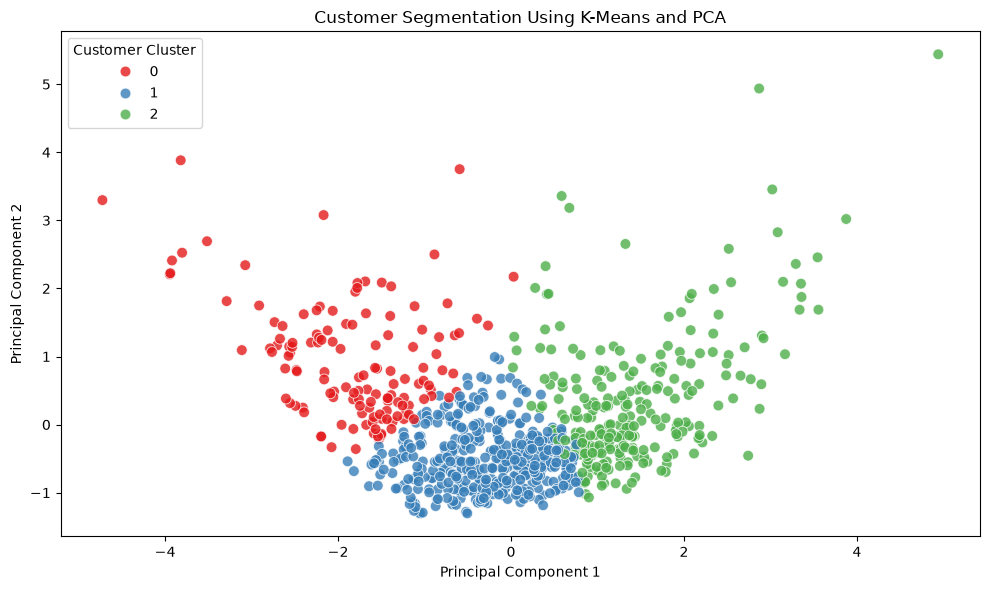

In [30]:

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame({
    "PC1": rfm_pca[:, 0],
    "PC2": rfm_pca[:, 1],
    "Cluster": labels_3
})

# Draw the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=60,
    alpha=0.8
)

plt.title("Customer Segmentation Using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.savefig("output/customer_segmentation_pca.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [23]:
print("Customers in RFM:", len(rfm))
print("Customers in scaled data:", rfm_scaled.shape[0])
print("Customers assigned to clusters:", len(labels_3))
print("Total customers across clusters:", rfm_3["Cluster"].value_counts().sum())
print("\nCluster counts:")
print(rfm_3["Cluster"].value_counts().sort_index())

Customers in RFM: 803
Customers in scaled data: 803
Customers assigned to clusters: 803
Total customers across clusters: 803

Cluster counts:
Cluster
0    136
1    415
2    252
Name: count, dtype: int64


In [24]:
persona_names = {
    0: "At-Risk Customers",
    1: "Regular Customers",
    2: "High-Value Loyal Customers"
}

rfm_3["Persona"] = rfm_3["Cluster"].map(persona_names)

print(rfm_3[["Customer ID", "Recency", "Frequency", "Monetary", "Cluster", "Persona"]].head())

  Customer ID  Recency  Frequency  Monetary  Cluster  \
0    AA-10315      117          5  5563.560        2   
1    AA-10375       47          8   906.518        1   
2    AA-10480      192          4  1790.512        1   
3    AA-10645      415          5  5073.975        0   
4    AB-10015      348          3   886.156        0   

                      Persona  
0  High-Value Loyal Customers  
1           Regular Customers  
2           Regular Customers  
3           At-Risk Customers  
4           At-Risk Customers  


In [25]:
persona_summary = rfm_3.groupby("Persona").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

persona_summary = persona_summary.sort_values(
    by="Avg_Monetary", ascending=False
)

print(persona_summary)

                            Customer_Count  Avg_Recency  Avg_Frequency  \
Persona                                                                  
High-Value Loyal Customers             252        93.98           8.38   
Regular Customers                      415       120.43           4.88   
At-Risk Customers                      136       551.85           3.34   

                            Avg_Monetary  
Persona                                   
High-Value Loyal Customers       4997.89  
Regular Customers                1603.73  
At-Risk Customers                1399.03  


In [27]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nDoes the output folder exist?")
print(os.path.exists("output"))

Current working directory:
c:\Users\USER\OneDrive\Desktop\CodeNova_Sales_Analysis\CodeNova_Task_4

Does the output folder exist?
False


In [28]:
import os

# Create the output folder if it doesn't exist
os.makedirs("output", exist_ok=True)

# Save the customer persona summary
persona_summary.to_csv("output/customer_persona_summary.csv")

print("Customer persona summary saved successfully!")

Customer persona summary saved successfully!


In [29]:
evaluation_results = pd.DataFrame({
    "Number_of_Clusters": [3, 4],
    "Silhouette_Score": [score_3, score_4]
})

evaluation_results.to_csv(
    "output/cluster_evaluation_results.csv",
    index=False
)

print(evaluation_results)
print("\nCluster evaluation results saved successfully!")

   Number_of_Clusters  Silhouette_Score
0                   3          0.340245
1                   4          0.337454

Cluster evaluation results saved successfully!
